# Santander Value Prediction — Data Understanding

**Dataset:** 4,459 rows × 4,991 anonymized predictors ([OpenML 42572](https://www.openml.org/search?id=42572&type=data)). **Target:** transaction value. **Metric:** RMSLE.

We inspect sparsity, data quality, and target skew to guide modeling. This EDA uses all labeled observations; descriptive findings are not an independent test evaluation.

## 1. Load data

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_openml


In [2]:
dataset = fetch_openml(
    data_id=42572,
    target_column="target",
    as_frame=True,
)

X = dataset.data
y = dataset.target

print("X shape:", X.shape)
print("y shape:", y.shape)


X shape: (4459, 4991)
y shape: (4459,)


## 2. Feature types

The input features are anonymized, so numerical data types do not establish business meaning.

In [3]:
display(X.iloc[:5, :5])
display(y.head())

print("Feature names:", X.columns[:10].tolist())
print("\nFeature data types:")
print(X.dtypes.value_counts())
print("\nTarget data type:", y.dtype)


,48df886f9,0deb4b6a8,34b15f335,a8cb14b00,2f0771a37
0,0.0,0,0.0,0,0
1,0.0,0,0.0,0,0
2,0.0,0,0.0,0,0
3,0.0,0,0.0,0,0
4,0.0,0,0.0,0,0


0    38000000.0
1      600000.0
2    10000000.0
3     2000000.0
4    14400000.0
Name: target, dtype: float64

Feature names: ['48df886f9', '0deb4b6a8', '34b15f335', 'a8cb14b00', '2f0771a37', '30347e683', 'd08d1fbe3', '6ee66e115', '20aa07010', 'dc5a8f1d8']

Feature data types:
int64      3147
float64    1844
Name: count, dtype: int64

Target data type: float64


## 3. Missing values and sparsity

Check missingness, constant columns, and the proportion of zeros before choosing preprocessing steps.

In [4]:
missing_values = X.isna().sum().sum()
constant_features = (X.nunique() == 1).sum()
zero_ratio = (X == 0).to_numpy().mean() * 100

print("Missing values:", missing_values)
print("Constant features:", constant_features)
print(f"Zero values: {zero_ratio:.2f}%")


Missing values: 0
Constant features: 256
Zero values: 96.85%


In [5]:
all_zero_cols = (X == 0).all().sum()
print("All-zero columns:", all_zero_cols)


All-zero columns: 256


**Finding:** No missing values; 256 constant columns (all zero); 96.85% of input values are zero. Zeros should not be treated as missing. Any feature removal during predictive modeling must be based on training data only.

## 4. Row-level sparsity

Count non-zero inputs per observation and examine their Spearman correlation with the target.

In [6]:
nonzero_per_customer = (X != 0).sum(axis=1)
print(nonzero_per_customer.describe())


count    4459.000000
mean      157.010316
std       212.085541
min         1.000000
25%        34.000000
50%       103.000000
75%       197.000000
max      1989.000000
dtype: float64


In [7]:
correlation = nonzero_per_customer.corr(y, method="spearman")
print("Spearman correlation:", correlation)


Spearman correlation: -0.04473937768591484


**Finding:** Median non-zero count = 103 (range: 1–1,989), with weak monotonic target association (Spearman ρ = −0.0447). Its predictive value remains an empirical question.

## 5. Target distribution

In [8]:
print(y.describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.95, 0.99]))
print("Zero targets:", (y == 0).sum())


count    4.459000e+03
mean     5.944923e+06
std      8.234312e+06
min      3.000000e+04
1%       3.500000e+04
25%      6.000000e+05
50%      2.260000e+06
75%      8.000000e+06
95%      2.400000e+07
99%      3.857143e+07
max      4.000000e+07
Name: target, dtype: float64
Zero targets: 0


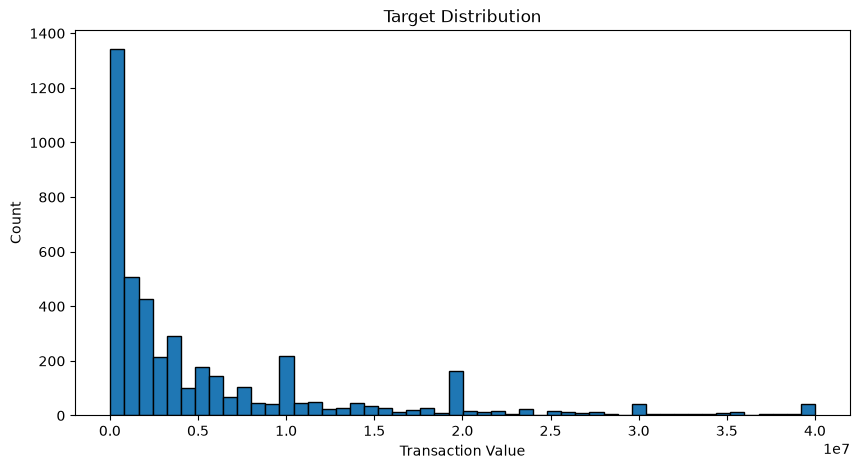

In [9]:
plt.figure(figsize=(10, 5))
plt.hist(y, bins=50, edgecolor="black")
plt.title("Target Distribution")
plt.xlabel("Transaction Value")
plt.ylabel("Count")
plt.show()


**Finding:** Target is strongly right-skewed: median 2.26M versus mean 5.94M (range: 30K–40M). Large values are not automatically invalid.

### Log-scale view

Inspect `log1p(target)` because RMSLE measures errors on this transformed scale.

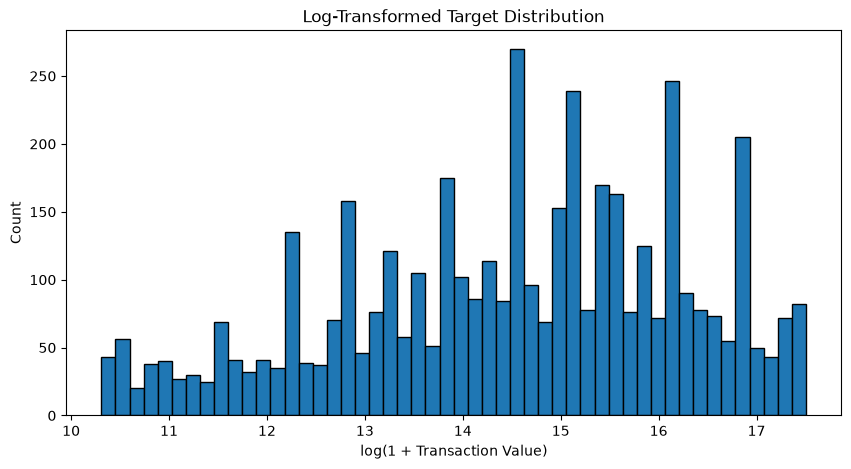

In [10]:
log_target = np.log1p(y)

plt.figure(figsize=(10, 5))
plt.hist(log_target, bins=50, edgecolor="black")
plt.title("Log-Transformed Target Distribution")
plt.xlabel("log(1 + Transaction Value)")
plt.ylabel("Count")
plt.show()


## Key takeaways

- **High dimensionality:** 4,991 predictors for 4,459 examples increases overfitting risk.
- **Strong sparsity:** 96.85% zeros; preserve zero semantics and test any engineered features empirically.
- **Skewed target:** use an RMSLE-aligned baseline before training feature-based models.

**Next:** Compare mean, median, and log-mean constant predictors.